# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170168          # <-- your full roll number
NAME = "Ujjwal Jain"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170168   Name: Ujjwal Jain   Fingerprint: E8F14304   Tickets: 15

Ticket_ID                                                                                 Ticket_Text
      T01                    I tried restarting the VPN after the latest update. It worked yesterday.
      T02                        MATLAB is not working since yesterday. It works on another computer.
      T03                                                                 My roll no. is 1023-03-021.
      T04                                                       Nothing works and nobody has replied.
      T05            I am unable to use the student portal when I use mobile hotspot. This is urgent.
      T06             I am unable to use the VPN while uploading the file. I don't know what changed.
      T07             I can't open the student portal after resetting my password. Please resolve it.
      T08                             The server was working yesterday. It works on another computer.

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
from collections import Counter

processed = [process_ticket(txt) for txt in df["Ticket_Text"]]
rows = []
totals = {"sentences": 0, "tokens": 0, "punctuation": 0, "stopwords": 0, "unique_tokens": 0, "final_tokens": 0}

for ticket_id, result in zip(df["Ticket_ID"], processed):
    row = {
        "Ticket_ID": ticket_id,
        "sentences": result["sentences"],
        "tokens": result["tokens"],
        "punctuation": result["punct"],
        "stopwords": result["stops"],
        "unique_tokens": sorted(set(result["tokens"])),
        "final_tokens": result["final"],
    }
    rows.append(row)
    totals["sentences"] += len(result["sentences"])
    totals["tokens"] += len(result["tokens"])
    totals["punctuation"] += len(result["punct"])
    totals["stopwords"] += len(result["stops"])
    totals["unique_tokens"] += len(set(result["tokens"]))
    totals["final_tokens"] += len(result["final"])

q1_table = pd.DataFrame(rows)
display(q1_table)
display(pd.DataFrame([{
    "Ticket_ID": "TOTAL",
    "sentences": totals["sentences"],
    "tokens": totals["tokens"],
    "punctuation": totals["punctuation"],
    "stopwords": totals["stopwords"],
    "unique_tokens": totals["unique_tokens"],
    "final_tokens": totals["final_tokens"],
}]))


,Ticket_ID,sentences,tokens,punctuation,stopwords,unique_tokens,final_tokens
0,T01,[I tried restarting the VPN after the latest u...,"[i, tried, restarting, the, vpn, after, the, l...","[., .]","[i, the, after, the, it]","[., after, i, it, latest, restarting, the, tri...","[tried, restarting, vpn, latest, update, worke..."
1,T02,"[MATLAB is not working since yesterday., It wo...","[matlab, is, not, working, since, yesterday, ....","[., .]","[is, not, it, on]","[., another, computer, is, it, matlab, not, on...","[matlab, working, since, yesterday, works, ano..."
2,T03,"[My roll no., is 1023-03-021.]","[my, roll, no, ., is, 1023-03-021, .]","[., .]","[my, no, is]","[., 1023-03-021, is, my, no, roll]","[roll, 1023-03-021]"
3,T04,[Nothing works and nobody has replied.],"[nothing, works, and, nobody, has, replied, .]",[.],"[and, has]","[., and, has, nobody, nothing, replied, works]","[nothing, works, nobody, replied]"
4,T05,[I am unable to use the student portal when I ...,"[i, am, unable, to, use, the, student, portal,...","[., .]","[i, am, to, the, when, i, this, is]","[., am, hotspot, i, is, mobile, portal, studen...","[unable, use, student, portal, use, mobile, ho..."
5,T06,[I am unable to use the VPN while uploading th...,"[i, am, unable, to, use, the, vpn, while, uplo...","[., .]","[i, am, to, the, while, the, i, do, what]","[., am, changed, do, file, i, know, n't, the, ...","[unable, use, vpn, uploading, file, n't, know,..."
6,T07,[I can't open the student portal after resetti...,"[i, ca, n't, open, the, student, portal, after...","[., .]","[i, the, after, my, it]","[., after, ca, i, it, my, n't, open, password,...","[ca, n't, open, student, portal, resetting, pa..."
7,T08,"[The server was working yesterday., It works o...","[the, server, was, working, yesterday, ., it, ...","[., .]","[the, was, it, on]","[., another, computer, it, on, server, the, wa...","[server, working, yesterday, works, another, c..."
8,T09,[The state-of-the-art lab (Lab-3) is closed.],"[the, state-of-the-art, lab, (, lab-3, ), is, ...","[(, ), .]","[the, is]","[(, ), ., closed, is, lab, lab-3, state-of-the...","[state-of-the-art, lab, lab-3, closed]"
9,T10,[Password has stopped syncing when connected t...,"[password, has, stopped, syncing, when, connec...","[., .]","[has, when, to, the, same, again]","[., again, campus, connected, has, occurs, pas...","[password, stopped, syncing, connected, campus..."


,Ticket_ID,sentences,tokens,punctuation,stopwords,unique_tokens,final_tokens
0,TOTAL,27,187,29,71,171,87


**Answer:** The final-token list can contain fragments such as `n't`, `'s`, and `ca`. They come from contractions (for example, *doesn't*, *it's*, and *can't*) being split by NLTK's `word_tokenize`. The pipeline lowercases tokens and removes punctuation and stopwords, but these contraction fragments may not be listed as stopwords, so they remain.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [10]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re
raw_texts = df["Ticket_Text"].tolist()
all_texts = raw_texts + TEST_LINES

# Optimized compiled regex patterns
number_pattern = re.compile(r"(?<![\w.])\d+(?:,\d{3})*(?:\.\d+)+(?:%?) | \b\d+(?:,\d{3})*(?:%?)", re.VERBOSE)
email_pattern = re.compile(r"\b[A-Za-z0-9.!#$%&'*+/=?^_`{|}~-]+@[A-Za-z0-9-]+(?:\.[A-Za-z0-9-]+)+\b")
url_pattern = re.compile(r"\b(?:https?://|www\.)[^\s<>]+")
phone_pattern = re.compile(r"(?<!\w)(?:\+?\d{1,3}[- ]?)?(?:\(?\d{3,5}\)?[- ]?)\d{3,5}[- ]?\d{3,5}(?!\w)")
long_word_pattern = re.compile(r"\b[A-Za-z]+(?:['’-][A-Za-z]+)*\b")
capitalized_pattern = re.compile(r"\b[A-Z][A-Za-z]*(?:['’-][A-Za-z]+)*\b")
vowel_pattern = re.compile(r"\b[AEIOUaeiou][A-Za-z]*(?:['’-][A-Za-z]+)*\b")

for i, text in enumerate(all_texts, start=1):
    print(f"\nTEXT {i}: {text}")
    # Optimized length calculation avoiding redundant object creation
    words_longer_5 = [
        w for w in long_word_pattern.findall(text)
        if sum(1 for ch in w if ch.isalpha()) > 5
    ]
    print("Words > 5 letters:", words_longer_5)
    print("Numbers:", number_pattern.findall(text))
    print("Capitalized words:", capitalized_pattern.findall(text))
    print("Words starting with a vowel:", vowel_pattern.findall(text))

    # Chained replacements
    redacted = email_pattern.sub("<EMAIL>", text)
    redacted = url_pattern.sub("<URL>", redacted)
    redacted = phone_pattern.sub("<PHONE>", redacted)
    print("Redacted:", redacted)

capitalized_by_text = [capitalized_pattern.findall(t) for t in all_texts]
sentence_initial_cap_count = sum(
    1 for t, words in zip(all_texts, capitalized_by_text)
    for w in words if t.startswith(w)
)
print("\nCapitalized matches that occur at the beginning of a text:", sentence_initial_cap_count)


TEXT 1: I tried restarting the VPN after the latest update. It worked yesterday.
Words > 5 letters: ['restarting', 'latest', 'update', 'worked', 'yesterday']
Numbers: []
Capitalized words: ['I', 'VPN', 'It']
Words starting with a vowel: ['I', 'after', 'update', 'It']
Redacted: I tried restarting the VPN after the latest update. It worked yesterday.

TEXT 2: MATLAB is not working since yesterday. It works on another computer.
Words > 5 letters: ['MATLAB', 'working', 'yesterday', 'another', 'computer']
Numbers: []
Capitalized words: ['MATLAB', 'It']
Words starting with a vowel: ['is', 'It', 'on', 'another']
Redacted: MATLAB is not working since yesterday. It works on another computer.

TEXT 3: My roll no. is 1023-03-021.
Words > 5 letters: []
Numbers: ['1023', '03', '021']
Capitalized words: ['My']
Words starting with a vowel: ['is']
Redacted: My roll no. is 1023-03-021.

TEXT 4: Nothing works and nobody has replied.
Words > 5 letters: ['Nothing', 'nobody', 'replied']
Numbers: []
Capita

**Answer:** The code above reports capitalized matches that occur at the beginning of a ticket. This is treated as an estimate rather than a perfect count: a capitalized word at the start of a sentence may also be a proper name or acronym, and sentences after the first are not counted by this simple beginning-of-text check.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [11]:
from nltk.tokenize import RegexpTokenizer, word_tokenize

TOKEN_PATTERN = (
    r"https?://[^\s<>]+|www\.[^\s<>]+|"
    r"[A-Za-z0-9.!#$%&'*+/=?^_`{|}~-]+@[A-Za-z0-9-]+(?:\.[A-Za-z0-9-]+)+|"
    r"(?:\+?\d{1,3}[- ]?)?(?:\(?\d{3,5}\)?[- ]?)\d{3,5}[- ]?\d{3,5}|"
    r"(?:\d+\.)+\d+(?:%?)|\d+(?:\.\d+)?%?|"
    r"[A-Za-z]+(?:['’][A-Za-z]+)+|"
    r"[A-Za-z0-9]+(?:-[A-Za-z0-9]+)+|"
    r"[A-Za-z]+|#[A-Za-z0-9_]+"
)
# Compilation happens automatically inside RegexpTokenizer, keeping it clean
regexp_tokenizer = RegexpTokenizer(TOKEN_PATTERN)

def my_tokenize(text):
    """Tokenize text while preserving URLs, emails, phone numbers, versions, decimals,
    contractions and hyphenated compounds as single tokens."""
    return regexp_tokenizer.tokenize(text)

print("TEST_LINES comparison:")
for line in TEST_LINES:
    print(f"\nText: {line}")
    print("Custom:", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))

# Efficiently build the comparison table
comparison_rows = []
different_ticket_ids = []

for ticket_id, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    custom = my_tokenize(text)
    standard = word_tokenize(text)
    differs = (custom != standard)
    if differs:
        different_ticket_ids.append(ticket_id)
    comparison_rows.append({
        "Ticket_ID": ticket_id,
        "Custom tokens": custom,
        "word_tokenize": standard,
        "Different?": differs
    })

display(pd.DataFrame(comparison_rows))
print(f"\nTickets tokenized differently: {len(different_ticket_ids)} of {len(df)}")
print("Ticket IDs:", different_ticket_ids)

TEST_LINES comparison:

Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom: ['Call', '91', '98765', '43210', '91', '98765', '43210', 'or', '0175-239-3201', 'Version', '2.0.1', 'is', '95.5%', 'done', 'fee', 'Rs', '1', '250']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Custom: ['The', '

,Ticket_ID,Custom tokens,word_tokenize,Different?
0,T01,"[I, tried, restarting, the, VPN, after, the, l...","[I, tried, restarting, the, VPN, after, the, l...",True
1,T02,"[MATLAB, is, not, working, since, yesterday, I...","[MATLAB, is, not, working, since, yesterday, ....",True
2,T03,"[My, roll, no, is, 1023, 03, 021]","[My, roll, no, ., is, 1023-03-021, .]",True
3,T04,"[Nothing, works, and, nobody, has, replied]","[Nothing, works, and, nobody, has, replied, .]",True
4,T05,"[I, am, unable, to, use, the, student, portal,...","[I, am, unable, to, use, the, student, portal,...",True
5,T06,"[I, am, unable, to, use, the, VPN, while, uplo...","[I, am, unable, to, use, the, VPN, while, uplo...",True
6,T07,"[I, can't, open, the, student, portal, after, ...","[I, ca, n't, open, the, student, portal, after...",True
7,T08,"[The, server, was, working, yesterday, It, wor...","[The, server, was, working, yesterday, ., It, ...",True
8,T09,"[The, state-of-the-art, lab, Lab-3, is, closed]","[The, state-of-the-art, lab, (, Lab-3, ), is, ...",True
9,T10,"[Password, has, stopped, syncing, when, connec...","[Password, has, stopped, syncing, when, connec...",True



Tickets tokenized differently: 15 of 15
Ticket IDs: ['T01', 'T02', 'T03', 'T04', 'T05', 'T06', 'T07', 'T08', 'T09', 'T10', 'T11', 'T12', 'T13', 'T14', 'T15']


**Answer:** The exact number and ticket IDs are printed by the code. A ticket is counted as different whenever the custom tokenizer's token list is not identical to `word_tokenize`'s list. Differences are expected because the custom tokenizer deliberately keeps contractions, hyphenated words, URLs, emails, phone numbers, and version/decimal strings together.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [12]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag

unique_final = sorted({token for result in processed for token in result["final"]})
porter = PorterStemmer()
lancaster = LancasterStemmer()
regex_stemmer = RegexpStemmer(r"(ing|edly|ed|ies|s)$", min=3)
lemmatizer = WordNetLemmatizer()

# Direct lookup dictionary mapping for faster performance
pos_map = {'J': 'a', 'V': 'v', 'N': 'n', 'R': 'r'}
def wordnet_pos(treebank_tag):
    return pos_map.get(treebank_tag[0], 'n') if treebank_tag else 'n'

tagged = pos_tag(unique_final)
tag_map = dict(tagged)
stem_rows = []

for word in unique_final:
    pos = wordnet_pos(tag_map.get(word, "NN"))

    # Pre-calculate stems/lemmas to make logic clear and clean
    p_stem = porter.stem(word)
    l_stem = lancaster.stem(word)
    r_stem = regex_stemmer.stem(word)
    wn_lemma = lemmatizer.lemmatize(word, pos=pos)

    # Add row only if there is a difference between any of the reduction techniques
    if len({p_stem, l_stem, r_stem, wn_lemma}) > 1:
        stem_rows.append({
            "word": word,
            "Porter": p_stem,
            "Lancaster": l_stem,
            "Regexp": r_stem,
            "WordNet lemma": wn_lemma,
            "POS tag": tag_map.get(word, "NN")
        })

stem_table = pd.DataFrame(stem_rows, columns=["word", "Porter", "Lancaster", "Regexp", "WordNet lemma", "POS tag"])
display(stem_table)
print(f"Unique final tokens: {len(unique_final)}; words with differing outputs: {len(stem_table)}")

,word,Porter,Lancaster,Regexp,WordNet lemma,POS tag
0,another,anoth,anoth,another,another,DT
1,assignment,assign,assign,assignment,assignment,JJ
2,campus,campu,camp,campu,campus,VB
3,changed,chang,chang,chang,change,VBN
4,closed,close,clos,clos,close,VBD
5,code,code,cod,code,code,NN
6,computer,comput,comput,computer,computer,NN
7,deadline,deadlin,deadlin,deadline,deadline,JJ
8,error,error,er,error,error,NN
9,file,file,fil,file,file,NN


Unique final tokens: 61; words with differing outputs: 35


**Answer:** Using the displayed comparison table to choose examples. **Over-stemming** occurs when a stemmer removes too much and produces an unnatural or misleading form. **Under-stemming** occurs when related forms remain different even though they share a root. The exact examples depend on the generated vocabulary and are shown in the table.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Tokens,Unique tokens,TTR
0,S1: all tokens,187,92,0.491979
1,S2: no punctuation,158,88,0.556962
2,S3: final tokens,87,61,0.701149
3,S4: S3 after Porter,87,59,0.678161


Top 10 words in S1:


,Word,Frequency
0,.,25
1,the,14
2,i,7
3,is,6
4,it,5
5,yesterday,4
6,working,4
7,works,3
8,on,3
9,another,3


Top 10 words in S3:


,Word,Frequency
0,yesterday,4
1,working,4
2,works,3
3,another,3
4,use,3
5,password,3
6,vpn,2
7,computer,2
8,unable,2
9,student,2


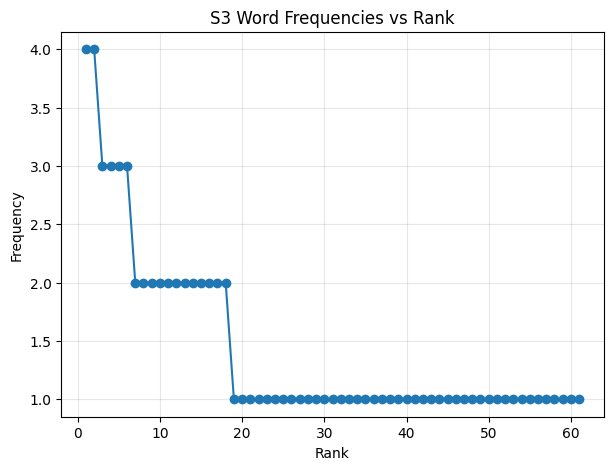

Top 5 bigrams in S1:


,Bigram,Frequency
0,"(., the)",6
1,"(., i)",5
2,"(yesterday, .)",4
3,"(., it)",3
4,"(the, vpn)",2


Top 5 bigrams in S3:


,Bigram,Frequency
0,"(yesterday, works)",2
1,"(works, another)",2
2,"(another, computer)",2
3,"(unable, use)",2
4,"(student, portal)",2


In [13]:
import matplotlib.pyplot as plt
from collections import Counter
from nltk.util import bigrams

# Flatten using list comprehensions
S1 = [token for result in processed for token in result["tokens"]]
S2 = [token for token in S1 if not is_punct(token)]
S3 = [token for result in processed for token in result["final"]]
S4 = [porter.stem(token) for token in S3]

def corpus_stats(name, tokens):
    unique = len(set(tokens))
    total = len(tokens)
    return {
        "Corpus": name,
        "Tokens": total,
        "Unique tokens": unique,
        "TTR": unique / total if total else 0
    }

stats = pd.DataFrame([
    corpus_stats("S1: all tokens", S1),
    corpus_stats("S2: no punctuation", S2),
    corpus_stats("S3: final tokens", S3),
    corpus_stats("S4: S3 after Porter", S4),
])
display(stats)

freq_s1 = Counter(S1)
freq_s3 = Counter(S3)

print("Top 10 words in S1:")
display(pd.DataFrame(freq_s1.most_common(10), columns=["Word", "Frequency"]))

print("Top 10 words in S3:")
display(pd.DataFrame(freq_s3.most_common(10), columns=["Word", "Frequency"]))

ranked_s3 = freq_s3.most_common()
ranks = list(range(1, len(ranked_s3) + 1))
frequencies = [f for _, f in ranked_s3]

plt.figure(figsize=(7, 5))
plt.plot(ranks, frequencies, marker="o", linestyle="-")
plt.xlabel("Rank")
plt.ylabel("Frequency")
plt.title("S3 Word Frequencies vs Rank")
plt.grid(True, alpha=0.3)
plt.show()

print("Top 5 bigrams in S1:")
display(pd.DataFrame(Counter(bigrams(S1)).most_common(5), columns=["Bigram", "Frequency"]))

print("Top 5 bigrams in S3:")
display(pd.DataFrame(Counter(bigrams(S3)).most_common(5), columns=["Bigram", "Frequency"]))


**Answer:** TTR is `unique tokens / total tokens`. Removing punctuation and stopwords changes both the number of tokens and the vocabulary, so S1 to S3 can change TTR substantially. Porter stemming (S3 to S4) merges some different word forms into the same stem, usually reducing the number of unique types; because the total token count stays the same, this can lower TTR.